# Diabetes Risk – EDA
Baran Toros, Berrin Şan

## Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Data

In [2]:
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")
print(df.shape)
df.head()

(253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

## Data Cleaning

In [4]:
# missing values
print("Missing values:", df.isnull().sum().sum())

# duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# BMI outliers
print("Rows with BMI > 70:", (df["BMI"] > 70).sum())
df = df[df["BMI"] <= 70]

# float -> int
df = df.astype(int)

# binary target (0 = no diabetes, 1 = prediabetes or diabetes)
df["Diabetes_binary"] = (df["Diabetes_012"] > 0).astype(int)

print("Shape after cleaning:", df.shape)

Missing values: 0
Duplicate rows: 23899


Rows with BMI > 70: 584
Shape after cleaning: (229197, 23)


## Descriptive Statistics

In [5]:
df[["BMI", "MentHlth", "PhysHlth", "GenHlth", "Age", "Income"]].describe().round(2)

,BMI,MentHlth,PhysHlth,GenHlth,Age,Income
count,229197.00,229197.00,229197.00,229197.00,229197.00,229197.00
mean,28.55,3.51,4.68,2.60,8.09,5.89
std,6.26,7.71,9.05,1.06,3.09,2.09
min,12.00,0.00,0.00,1.00,1.00,1.00
25%,24.00,0.00,0.00,2.00,6.00,4.00
50%,27.00,0.00,0.00,3.00,8.00,6.00
75%,32.00,2.00,4.00,3.00,10.00,8.00
max,70.00,30.00,30.00,5.00,13.00,8.00


## Skewness

In [6]:
df[["BMI", "MentHlth", "PhysHlth"]].skew().round(2)

BMI         1.19
MentHlth    2.55
PhysHlth    2.05
dtype: float64

In [7]:
# log transformation
for col in ["BMI", "MentHlth", "PhysHlth"]:
    print(col, round(df[col].skew(), 2), "->", round(np.log1p(df[col]).skew(), 2))

BMI 1.19 -> 0.42
MentHlth 2.55 -> 1.38
PhysHlth 2.05 -> 1.1


## Scaling Plan

In [8]:
# will be used in assignment 2 (after train/test split)
continuous_cols = ["BMI", "MentHlth", "PhysHlth"]        # StandardScaler
ordinal_cols = ["GenHlth", "Age", "Education", "Income"]   # MinMaxScaler
binary_cols = [c for c in df.columns if df[c].nunique() == 2 and c != "Diabetes_binary"]
print("Binary columns:", len(binary_cols))

Binary columns: 14


## Class Distribution

In [9]:
print(df["Diabetes_012"].value_counts())
print((df["Diabetes_012"].value_counts(normalize=True) * 100).round(1))

Diabetes_012
0    189559
2     35021
1      4617
Name: count, dtype: int64
Diabetes_012
0    82.7
2    15.3
1     2.0
Name: proportion, dtype: float64


## Graphs

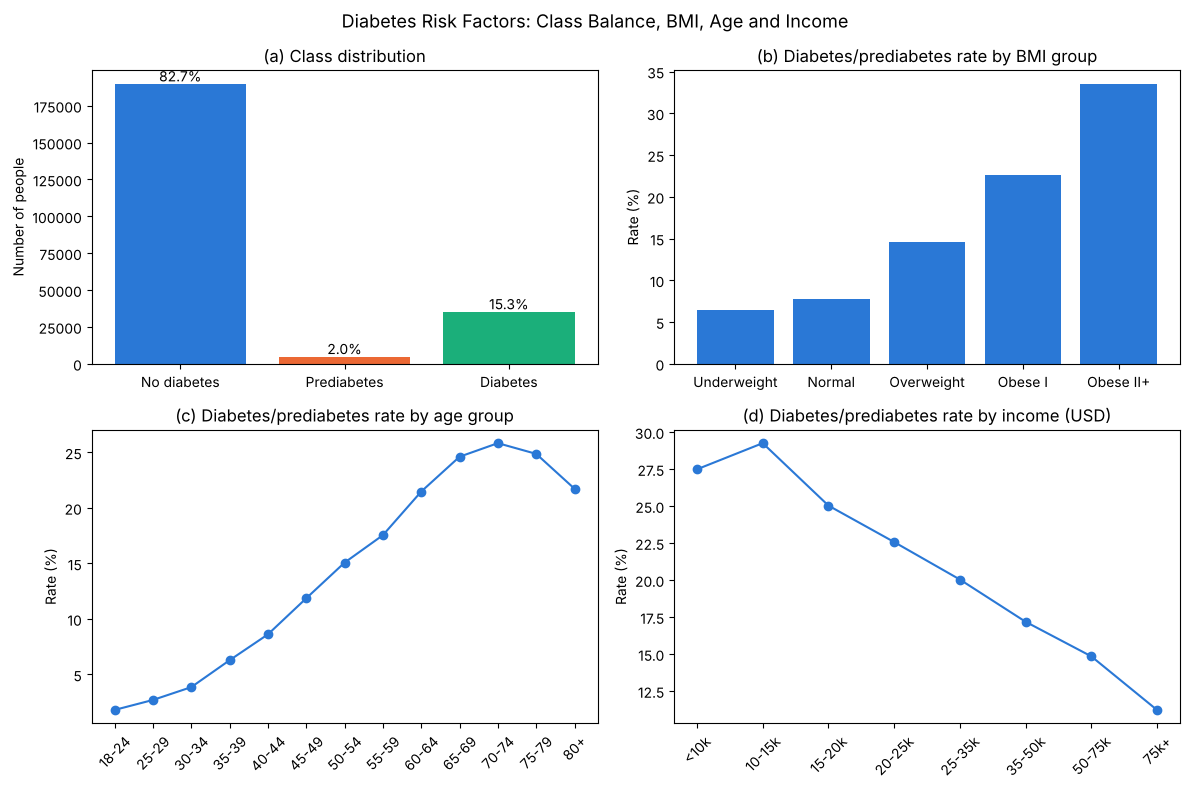

In [10]:
age_labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
income_labels = ["<10k", "10-15k", "15-20k", "20-25k", "25-35k", "35-50k", "50-75k", "75k+"]
df["BMI_group"] = pd.cut(df["BMI"], bins=[0, 18.5, 25, 30, 35, 100], right=False,
                         labels=["Underweight", "Normal", "Overweight", "Obese I", "Obese II+"])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# class distribution
counts = df["Diabetes_012"].value_counts().sort_index()
bars = axes[0, 0].bar(["No diabetes", "Prediabetes", "Diabetes"], counts.values, color=["#2a78d6", "#eb6834", "#1baf7a"])
for b, v in zip(bars, counts.values):
    axes[0, 0].text(b.get_x() + b.get_width() / 2, v + 2000, f"{v / counts.sum():.1%}", ha="center")
axes[0, 0].set_title("(a) Class distribution")
axes[0, 0].set_ylabel("Number of people")

# BMI
r = df.groupby("BMI_group", observed=True)["Diabetes_binary"].mean() * 100
axes[0, 1].bar(r.index.astype(str), r.values, color="#2a78d6")
axes[0, 1].set_title("(b) Diabetes/prediabetes rate by BMI group")
axes[0, 1].set_ylabel("Rate (%)")

# age
r = df.groupby("Age")["Diabetes_binary"].mean() * 100
axes[1, 0].plot(age_labels, r.values, marker="o", color="#2a78d6")
axes[1, 0].set_title("(c) Diabetes/prediabetes rate by age group")
axes[1, 0].set_ylabel("Rate (%)")
axes[1, 0].tick_params(axis="x", rotation=45)

# income
r = df.groupby("Income")["Diabetes_binary"].mean() * 100
axes[1, 1].plot(income_labels, r.values, marker="o", color="#2a78d6")
axes[1, 1].set_title("(d) Diabetes/prediabetes rate by income (USD)")
axes[1, 1].set_ylabel("Rate (%)")
axes[1, 1].tick_params(axis="x", rotation=45)

fig.suptitle("Diabetes Risk Factors: Class Balance, BMI, Age and Income", fontsize=13)
plt.tight_layout()
plt.savefig("fig_risk_factors.png", dpi=200)
plt.show()

In [11]:
print((df.groupby("BMI_group", observed=True)["Diabetes_binary"].mean() * 100).round(1))
print((df.groupby("Age")["Diabetes_binary"].mean() * 100).round(1))
print((df.groupby("Income")["Diabetes_binary"].mean() * 100).round(1))

BMI_group
Underweight     6.5
Normal          7.8
Overweight     14.6
Obese I        22.7
Obese II+      33.5
Name: Diabetes_binary, dtype: float64
Age
1      1.8
2      2.7
3      3.9
4      6.3
5      8.6
6     11.9
7     15.1
8     17.5
9     21.5
10    24.6
11    25.8
12    24.9
13    21.7
Name: Diabetes_binary, dtype: float64
Income
1    27.5
2    29.3
3    25.0
4    22.6
5    20.0
6    17.2
7    14.8
8    11.2
Name: Diabetes_binary, dtype: float64


## Correlation

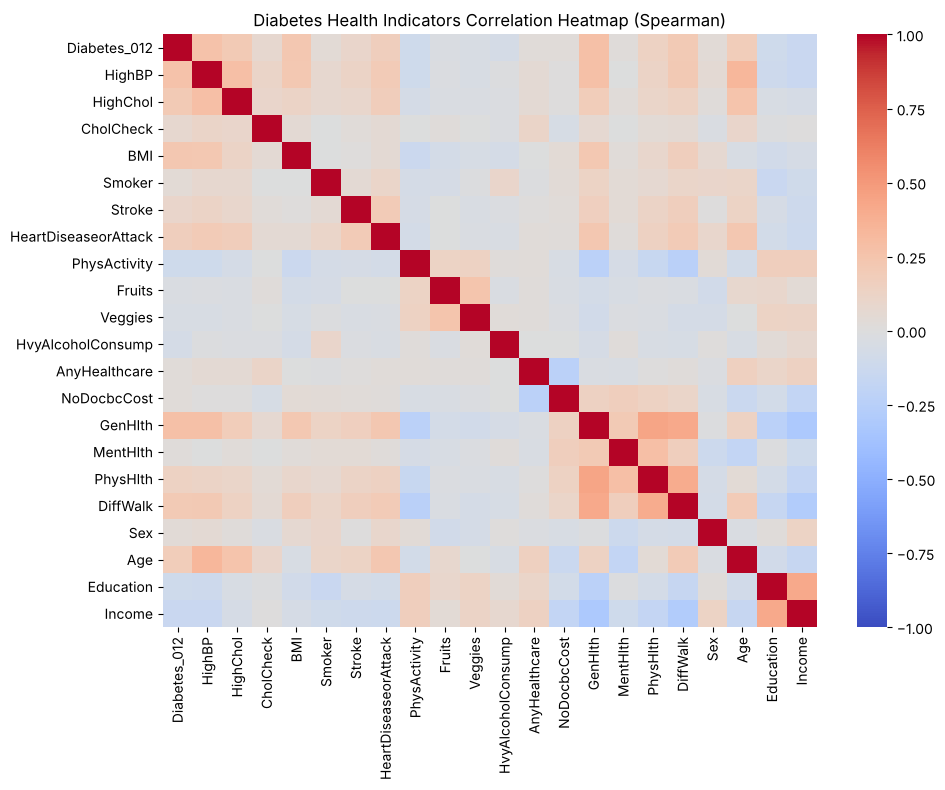

In [12]:
# spearman (most columns are 0/1 or ordinal)
corr = df.drop(columns=["Diabetes_binary", "BMI_group"]).corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Diabetes Health Indicators Correlation Heatmap (Spearman)")
plt.tight_layout()
plt.savefig("fig_heatmap.png", dpi=200)
plt.show()

In [13]:
# correlation with target
corr["Diabetes_012"].drop("Diabetes_012").sort_values(ascending=False).round(2)

GenHlth                 0.28
HighBP                  0.26
BMI                     0.23
DiffWalk                0.21
HighChol                0.20
Age                     0.18
HeartDiseaseorAttack    0.17
PhysHlth                0.14
Stroke                  0.10
CholCheck               0.08
Smoker                  0.05
Sex                     0.03
NoDocbcCost             0.02
AnyHealthcare           0.02
MentHlth                0.02
Fruits                 -0.03
Veggies                -0.04
HvyAlcoholConsump      -0.07
Education              -0.10
PhysActivity           -0.10
Income                 -0.15
Name: Diabetes_012, dtype: float64

## Multicollinearity

In [14]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high = upper.stack()[upper.stack().abs() > 0.85]
print("Pairs with correlation > 0.85:", len(high))
print("Highest correlation:", upper.drop(index="Diabetes_012", columns="Diabetes_012").abs().max().max().round(2))

Pairs with correlation > 0.85: 0
Highest correlation: 0.44


## Save Clean Data

In [15]:
df.drop(columns=["BMI_group"]).to_csv("diabetes_clean.csv", index=False)
print(df.drop(columns=["BMI_group"]).shape)

(229197, 23)


## Results
- 23,899 duplicates and 584 BMI outliers removed, 229,197 rows left
- Classes are imbalanced: 82.7% / 2.0% / 15.3%
- Risk increases with BMI and age, decreases with income
- Most related to diabetes: GenHlth, HighBP, BMI
- No pair above 0.85, all features kept